## 0 - Introduction

# Notebook 03 – Data Augmentation

## Objective

This notebook implements data augmentation for the CamVid
road-scene image classification project.

The objective is to improve model generalization by introducing
controlled variations in training images.

The notebook reuses the dataset preparation, class labels,
image paths, and sequence-based train/validation/test splits
generated in Notebook 02.

### Key principles

1. Augmentation is applied only to training images.
2. Validation and test images remain unchanged.
3. Image dimensions and aspect ratio are preserved.
4. Multi-label targets remain unchanged.
5. Original dataset files are never modified.

### Augmentation techniques

- Horizontal flipping
- Brightness adjustment
- Contrast adjustment
- Saturation adjustment
- Small-angle rotation
- Minor translation and scaling
- Optional Gaussian blur

## 1. Imports and configurations

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Project configuration
PROJECT_ROOT = Path("/content/drive/MyDrive/AAI-521/project")

DATASET_DIR = PROJECT_ROOT / "datasets" / "camvid"
IMAGE_DIR = DATASET_DIR / "images"

OUTPUT_DIR = DATASET_DIR / "preprocessed"

METADATA_CSV = (
    OUTPUT_DIR / "camvid_preprocessed_metadata.csv"
)

ACTIVE_CLASSES_CSV = (
    OUTPUT_DIR / "active_classes.csv"
)

# Image configuration
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_WORKERS = 2

# Padding configuration inherited from Notebook 02
PADDING_COLOR = (124, 116, 104)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Dataset directory exists:", DATASET_DIR.exists())
print("Preprocessed directory exists:", OUTPUT_DIR.exists())
print("Metadata CSV exists:", METADATA_CSV.exists())
print("Active classes CSV exists:", ACTIVE_CLASSES_CSV.exists())

Device: cuda
Dataset directory exists: True
Preprocessed directory exists: True
Metadata CSV exists: True
Active classes CSV exists: True


## 2. Load preprocessing artifacts

In [3]:
assert METADATA_CSV.exists(), (
    "Preprocessing metadata not found. "
    "Execute Notebook 02 first."
)

assert ACTIVE_CLASSES_CSV.exists(), (
    "Active class list not found. "
    "Execute Notebook 02 first."
)

df = pd.read_csv(METADATA_CSV)

ACTIVE_CLASSES = pd.read_csv(
    ACTIVE_CLASSES_CSV
)["class_name"].tolist()

print("Dataset shape:", df.shape)
print("Active classes:", len(ACTIVE_CLASSES))

print("\nSplit distribution:")
display(df["split"].value_counts())

print("\nActive classes:")
print(ACTIVE_CLASSES)

display(df.head())

Dataset shape: (701, 41)
Active classes: 29

Split distribution:


,count
split,
train,406
validation,171
test,124



Active classes:
['Road', 'Sky', 'Column_Pole', 'LaneMkgsDriv', 'Building', 'Sidewalk', 'Car', 'Pedestrian', 'Tree', 'Misc_Text', 'TrafficLight', 'Wall', 'OtherMoving', 'SignSymbol', 'Bicyclist', 'Fence', 'SUVPickupTruck', 'VegetationMisc', 'CartLuggagePram', 'ParkingBlock', 'Truck_Bus', 'Child', 'Archway', 'RoadShoulder', 'Animal', 'TrafficCone', 'MotorcycleScooter', 'LaneMkgsNonDriv', 'Bridge']


,image,filename,mask,Animal,Archway,Bicyclist,Bridge,Building,Car,CartLuggagePram,...,Tunnel,VegetationMisc,Wall,number_of_classes,sequence_id,split,image_path,mask_path,image_exists,mask_exists
0,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006690,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,0,...,0,0,0,14,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True
1,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006720,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,0,0,0,15,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True
2,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006750,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,0,0,0,15,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True
3,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006780,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,0,0,1,1,1,...,0,0,0,15,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True
4,/content/drive/MyDrive/AAI-521/project/dataset...,0001TP_006810,/content/drive/MyDrive/AAI-521/project/dataset...,0,0,1,0,1,1,1,...,0,0,0,18,0001TP,test,/content/drive/MyDrive/AAI-521/project/dataset...,/content/drive/MyDrive/AAI-521/project/dataset...,True,True


## 3. Validate loaded dataset

In [4]:
required_columns = [
    "filename",
    "image_path",
    "split"
] + ACTIVE_CLASSES

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)

assert df["filename"].is_unique, (
    "Duplicate filenames found."
)

assert set(df["split"].unique()) == {
    "train", "validation", "test"
}, "Unexpected dataset split values."

assert df["image_path"].apply(
    lambda path: Path(path).is_file()
).all(), "One or more image files are missing."

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "validation"].copy()
test_df = df[df["split"] == "test"].copy()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTotal samples:", len(df))
print("Total active classes:", len(ACTIVE_CLASSES))

assert len(train_df) + len(val_df) + len(test_df) == len(df)

Training samples: 406
Validation samples: 171
Testing samples: 124

Total samples: 701
Total active classes: 29


## 4. Define preprocessing and augmentation transformations
- Horizontal flip: introduces left-right variation.
- Color jitter: simulates lighting and color variations.
- Small affine transformation: introduces minor rotation, translation and scaling.
- Gaussian blur: simulates mild camera focus or motion blur.

In [16]:

# --------------------------------------------------
# 1. Deterministic resizing
# --------------------------------------------------

resize_transform = transforms.Resize((168, 224))

pad_transform = transforms.Pad(
    padding=(0, 28, 0, 28),
    fill=PADDING_COLOR
)


# --------------------------------------------------
# 2. Training augmentation
# --------------------------------------------------

augmentation_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.0
    ),

    transforms.RandomAffine(
        degrees=3,
        translate=(0.02, 0.02),
        scale=(0.98, 1.02),
        fill=PADDING_COLOR
    ),

    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 1.0)
            )
        ],
        p=0.15
    )
])


# --------------------------------------------------
# 3. Final transformation pipelines
# --------------------------------------------------

train_transform = transforms.Compose([
    resize_transform,
    augmentation_transform,
    pad_transform,
    transforms.ToTensor()
])

evaluation_transform = transforms.Compose([
    resize_transform,
    pad_transform,
    transforms.ToTensor()
])

print("Updated training transformation:")
print(train_transform)

print("\nUpdated evaluation transformation:")
print(evaluation_transform)

Updated training transformation:
Compose(
    Resize(size=(168, 224), interpolation=bilinear, max_size=None, antialias=True)
    Compose(
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=(0.9, 1.1), hue=None)
    RandomAffine(degrees=[-3.0, 3.0], translate=(0.02, 0.02), scale=(0.98, 1.02), fill=(124, 116, 104))
    RandomApply(
    p=0.15
    GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 1.0))
)
)
    Pad(padding=(0, 28, 0, 28), fill=(124, 116, 104), padding_mode=constant)
    ToTensor()
)

Updated evaluation transformation:
Compose(
    Resize(size=(168, 224), interpolation=bilinear, max_size=None, antialias=True)
    Pad(padding=(0, 28, 0, 28), fill=(124, 116, 104), padding_mode=constant)
    ToTensor()
)


## 5. Dataset implementation

In [17]:
class CamVidClassificationDataset(Dataset):

    def __init__(self, metadata, active_classes, transform=None):
        self.metadata = metadata.reset_index(drop=True)
        self.active_classes = active_classes
        self.transform = transform

    def __len__(self):
        return len(self.metadata)

    def __getitem__(self, index):

        row = self.metadata.iloc[index]

        image_path = Path(row["image_path"])

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        # Apply preprocessing and augmentation
        if self.transform:
            image = self.transform(image)

        # Preserve the original multi-label targets
        labels = torch.tensor(
            row[self.active_classes].values.astype(np.float32),
            dtype=torch.float32
        )

        return {
            "image": image,
            "labels": labels,
            "filename": row["filename"]
        }

## 6. Create datasets and validate samples

In [18]:
train_dataset = CamVidClassificationDataset(
    metadata=train_df,
    active_classes=ACTIVE_CLASSES,
    transform=train_transform
)

val_dataset = CamVidClassificationDataset(
    metadata=val_df,
    active_classes=ACTIVE_CLASSES,
    transform=evaluation_transform
)

test_dataset = CamVidClassificationDataset(
    metadata=test_df,
    active_classes=ACTIVE_CLASSES,
    transform=evaluation_transform
)

print("Training dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))
print("Testing dataset size:", len(test_dataset))

Training dataset size: 406
Validation dataset size: 171
Testing dataset size: 124


In [19]:
train_sample = train_dataset[0]
val_sample = val_dataset[0]
test_sample = test_dataset[0]

for name, sample in [
    ("Training", train_sample),
    ("Validation", val_sample),
    ("Testing", test_sample)
]:
    print(f"\n{name} sample:")
    print("Filename:", sample["filename"])
    print("Image shape:", sample["image"].shape)
    print("Label shape:", sample["labels"].shape)
    print("Image minimum:", sample["image"].min().item())
    print("Image maximum:", sample["image"].max().item())
    print("Number of positive labels:", sample["labels"].sum().item())


Training sample:
Filename: 0006R0_f00930
Image shape: torch.Size([3, 224, 224])
Label shape: torch.Size([29])
Image minimum: 0.0235294122248888
Image maximum: 1.0
Number of positive labels: 16.0

Validation sample:
Filename: Seq05VD_f00000
Image shape: torch.Size([3, 224, 224])
Label shape: torch.Size([29])
Image minimum: 0.0313725508749485
Image maximum: 1.0
Number of positive labels: 10.0

Testing sample:
Filename: 0001TP_006690
Image shape: torch.Size([3, 224, 224])
Label shape: torch.Size([29])
Image minimum: 0.01568627543747425
Image maximum: 1.0
Number of positive labels: 14.0


## 7. Visualize individual augmentation techniques

In [20]:
# Load and preprocess an original training image
sample_row = train_df.iloc[0]

sample_image_path = Path(sample_row["image_path"])

with Image.open(sample_image_path) as img:
    original_image = img.convert("RGB")

# Apply deterministic preprocessing only
base_image = base_preprocessing(original_image)

print("Original image size:", original_image.size)
print("Preprocessed image size:", base_image.size)

Original image size: (960, 720)
Preprocessed image size: (224, 224)


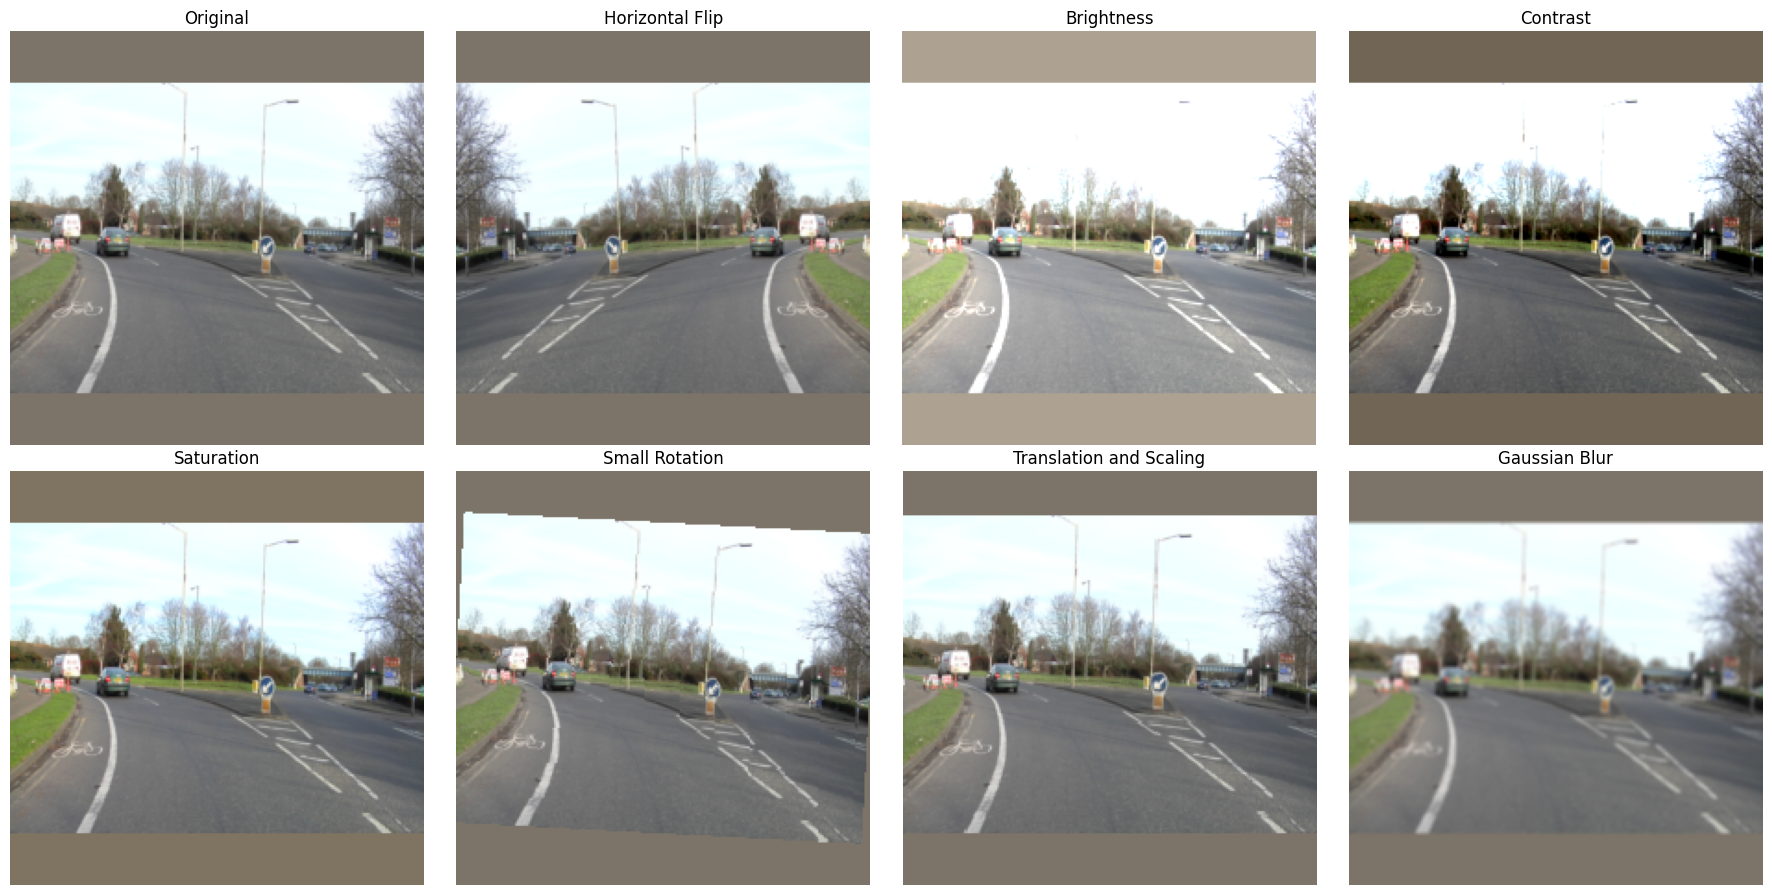

In [21]:
# Visualize individual transformations
augmentation_examples = {
    "Original": base_image,

    "Horizontal Flip": transforms.RandomHorizontalFlip(
        p=1.0
    )(base_image),

    "Brightness": transforms.ColorJitter(
        brightness=(1.4, 1.4)
    )(base_image),

    "Contrast": transforms.ColorJitter(
        contrast=(1.4, 1.4)
    )(base_image),

    "Saturation": transforms.ColorJitter(
        saturation=(1.5, 1.5)
    )(base_image),

    "Small Rotation": transforms.RandomAffine(
        degrees=(3, 3),
        fill=PADDING_COLOR
    )(base_image),

    "Translation and Scaling": transforms.RandomAffine(
        degrees=0,
        translate=(0.02, 0.02),
        scale=(1.02, 1.02),
        fill=PADDING_COLOR
    )(base_image),

    "Gaussian Blur": transforms.GaussianBlur(
        kernel_size=3,
        sigma=1.0
    )(base_image)
}

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, (title, image) in zip(
    axes.flat,
    augmentation_examples.items()
):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Visualize the combined augmentation pipeline

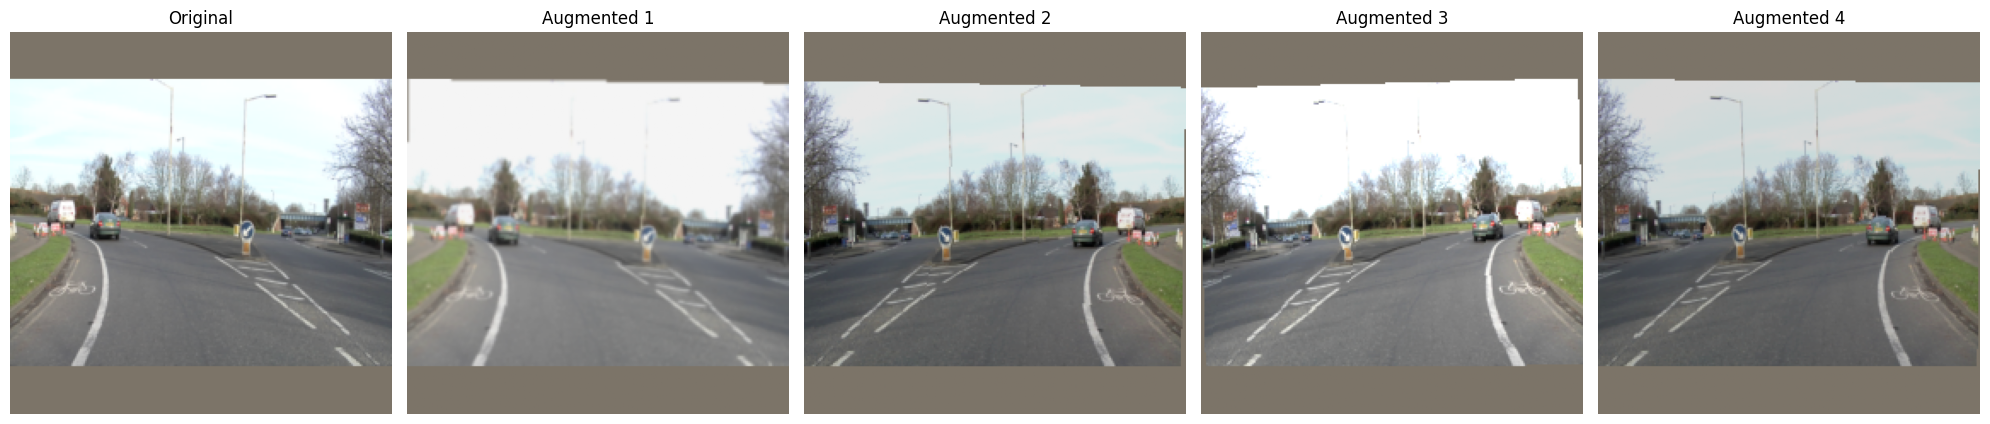

In [22]:
# Generate multiple augmented versions
# Generate multiple versions of the same training image
augmented_samples = [
    train_dataset[0]["image"]
    for _ in range(4)
]

# Convert tensors to displayable images
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

# Original preprocessed image
axes[0].imshow(base_image)
axes[0].set_title("Original")

# Four independently augmented versions
for i, image_tensor in enumerate(augmented_samples):
    image = image_tensor.permute(1, 2, 0).numpy()

    axes[i + 1].imshow(image)
    axes[i + 1].set_title(f"Augmented {i + 1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# Verify label consistency
sample_1 = train_dataset[0]
sample_2 = train_dataset[0]

print(
    "Labels identical:",
    torch.equal(sample_1["labels"], sample_2["labels"])
)

print(
    "Images identical:",
    torch.equal(sample_1["image"], sample_2["image"])
)

assert torch.equal(
    sample_1["labels"],
    sample_2["labels"]
), "Labels changed during augmentation!"

print("Label consistency validation passed.")

Labels identical: True
Images identical: False
Label consistency validation passed.


## 9. Create DataLoaders

In [24]:
# Create DataLoaders
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 13
Validation batches: 6
Testing batches: 4


In [25]:
# Validate a training batch
batch = next(iter(train_loader))

images = batch["image"]
labels = batch["labels"]
filenames = batch["filename"]

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Number of filenames:", len(filenames))

print("Image value range:",
      images.min().item(),
      "to",
      images.max().item())

print("Labels value range:",
      labels.min().item(),
      "to",
      labels.max().item())

assert images.shape[1:] == (3, 224, 224)
assert labels.shape[1] == len(ACTIVE_CLASSES)
assert len(filenames) == images.shape[0]

print("\nTraining batch validation passed.")

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32, 29])
Number of filenames: 32
Image value range: 0.0 to 1.0
Labels value range: 0.0 to 1.0

Training batch validation passed.


## 10. Save augmentation configuration

In [26]:
# Save configuration
augmentation_config = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "active_classes": ACTIVE_CLASSES,
    "training_augmentations": {
        "horizontal_flip_probability": 0.5,
        "brightness": 0.15,
        "contrast": 0.15,
        "saturation": 0.10,
        "rotation_degrees": 3,
        "translation": [0.02, 0.02],
        "scale": [0.98, 1.02],
        "gaussian_blur_probability": 0.15
    },
    "evaluation_augmentation": False
}

CONFIG_PATH = OUTPUT_DIR / "augmentation_config.json"

with open(CONFIG_PATH, "w") as f:
    json.dump(augmentation_config, f, indent=4)

print("Configuration saved to:", CONFIG_PATH)

Configuration saved to: /content/drive/MyDrive/AAI-521/project/datasets/camvid/preprocessed/augmentation_config.json
